# LFPG – локальная доступность траекторий

**Этап 01 · 12 октября 2026**

Вопрос: содержат ли сохраненные локальные источники последовательные наблюдения, из которых можно построить пилот конечного захода LFPG?

Область аудита: исходная европейская таблица версии 1.0 и 11 CSV из прежнего манифеста траекторий. Проверяются фактическая схема, контрольные суммы и наличие координат в широком поисковом прямоугольнике вокруг LFPG. Это ограниченная инвентаризация, не полный поиск всех возможных источников и не разметка заходов.

In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display

# Находим внешний исторический источник через общий реестр
BASE = Path.cwd()
if BASE.name == 'notebooks':
    BASE = BASE.parent
PROJECT = BASE.parents[1]
config = json.loads((PROJECT / 'configs/sources.json').read_text(encoding='utf-8'))
OLD = (PROJECT / config['airport_summary']).resolve().parents[2]
for name in ['reports', 'figures']:
    (BASE / name).mkdir(exist_ok=True)
RED, GREEN = '#D65A4A', '#00897B'
plt.rcParams.update({'figure.dpi': 130, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
manifest_path = OLD / 'research/final-approach-dynamics/reports/00_inventory_manifest.json'
manifest = json.loads(manifest_path.read_text(encoding='utf-8'))

# Читаем только метаданные Parquet без загрузки миллионов строк
parquet_path = OLD / 'europe/data/source/osn23_landings_merged.parquet.gzip'
with pq.ParquetFile(parquet_path) as parquet:
    schema = pd.DataFrame([{'field': field.name, 'type': str(field.type)}
                           for field in parquet.schema_arrow])
    parquet_rows = parquet.metadata.num_rows
schema.to_csv(BASE / 'reports/01_source_schema.csv', index=False)
print('Строк в исходном Parquet:', parquet_rows)
display(schema)

,field,type
0,flight_id,string
1,callsign,string
2,icao24,string
3,landing_time,"timestamp[ns, tz=UTC]"
4,registration,string
5,typecode,string
6,icaoaircrafttype,string
7,airport,string
8,country,string
9,attempt_times,"list<element: timestamp[us, tz=UTC]>"


Строк в исходном Parquet: 7984254


## Проверка сохраненных временных рядов

Поисковый прямоугольник **48,7–49,3° N; 2,0–3,0° E** намеренно широк. Координаты в нем означают только пространственных кандидатов, включая возможные пролеты и соседние аэропорты. Нулевое число кандидатов относится только к проверенным файлам. Порог не используется для определения ВПП, захвата ILS или события GoA.

Контрольная сумма каждого CSV сравнивается с прежним манифестом. Метки GoA не выводятся из самого факта наличия траектории.

In [2]:
rows = []
fields = []
for item in manifest['sources']:
    path = OLD / item['source']
    if not path.is_file():
        rows.append({'source': item['source'], 'status': 'Файл отсутствует'})
        continue
    # Проверяем происхождение до анализа содержимого
    with path.open('rb') as stream:
        digest = hashlib.file_digest(stream, 'sha256').hexdigest()
    frame = pd.read_csv(path, dtype={'icao24': str})
    # Считаем пространственных кандидатов без присвоения аэропорта
    candidate = frame['lat'].between(48.7, 49.3) & frame['lon'].between(2.0, 3.0)
    label_fields = [name for name in frame.columns
                    if name.lower() in {'goa', 'has_ga', 'go_around', 'go_arounds'}]
    rows.append({'source': item['source'], 'status': 'Проверен',
                 'sha256': digest, 'matches_manifest': digest == item['sha256'],
                 'rows': len(frame), 'candidate_rows': int(candidate.sum()),
                 'candidate_aircraft': frame.loc[candidate, 'icao24'].nunique(),
                 'label_fields': ', '.join(label_fields) or 'Отсутствуют'})
    for name in frame.columns:
        fields.append({'source': item['source'], 'field': name,
                       'nonmissing_rows': int(frame[name].notna().sum())})
inventory = pd.DataFrame(rows)
inventory.to_csv(BASE / 'reports/01_local_trajectory_inventory.csv', index=False)
pd.DataFrame(fields).to_csv(BASE / 'reports/01_trajectory_fields.csv', index=False)
display(inventory[['source', 'status', 'matches_manifest', 'rows',
                   'candidate_rows', 'candidate_aircraft', 'label_fields']])
assert inventory['status'].eq('Проверен').all(), 'Инвентаризация неполна'
assert inventory['matches_manifest'].all(), 'Исходники изменились относительно манифеста'
print('Проверено файлов:', len(inventory))
print('Строк в поисковом прямоугольнике:', int(inventory.candidate_rows.sum()))

,source,status,matches_manifest,rows,candidate_rows,candidate_aircraft,label_fields
0,research/c40_geometry/data/expanded_training/2...,Проверен,True,1811,0,0,Отсутствуют
1,research/c40_geometry/data/expanded_training/2...,Проверен,True,1790,0,0,Отсутствуют
2,research/c40_geometry/data/expanded_training/2...,Проверен,True,3040,0,0,Отсутствуют
3,research/c40_geometry/data/expanded_training/2...,Проверен,True,1903,0,0,Отсутствуют
4,research/c40_geometry/data/expanded_training/2...,Проверен,True,2474,0,0,Отсутствуют
5,research/c40_geometry/data/external_day/state_...,Проверен,True,2236,0,0,Отсутствуют
6,research/c40_geometry/data/hermite_validation/...,Проверен,True,1761,0,0,Отсутствуют
7,research/c40_geometry/data/hermite_validation/...,Проверен,True,2240,0,0,Отсутствуют
8,research/c40_geometry/data/public_pilot/ENT73J...,Проверен,True,359,0,0,Отсутствуют
9,research/c40_geometry/data/public_pilot/ENT73J...,Проверен,True,130,0,0,Отсутствуют


Проверено файлов: 11
Строк в поисковом прямоугольнике: 0


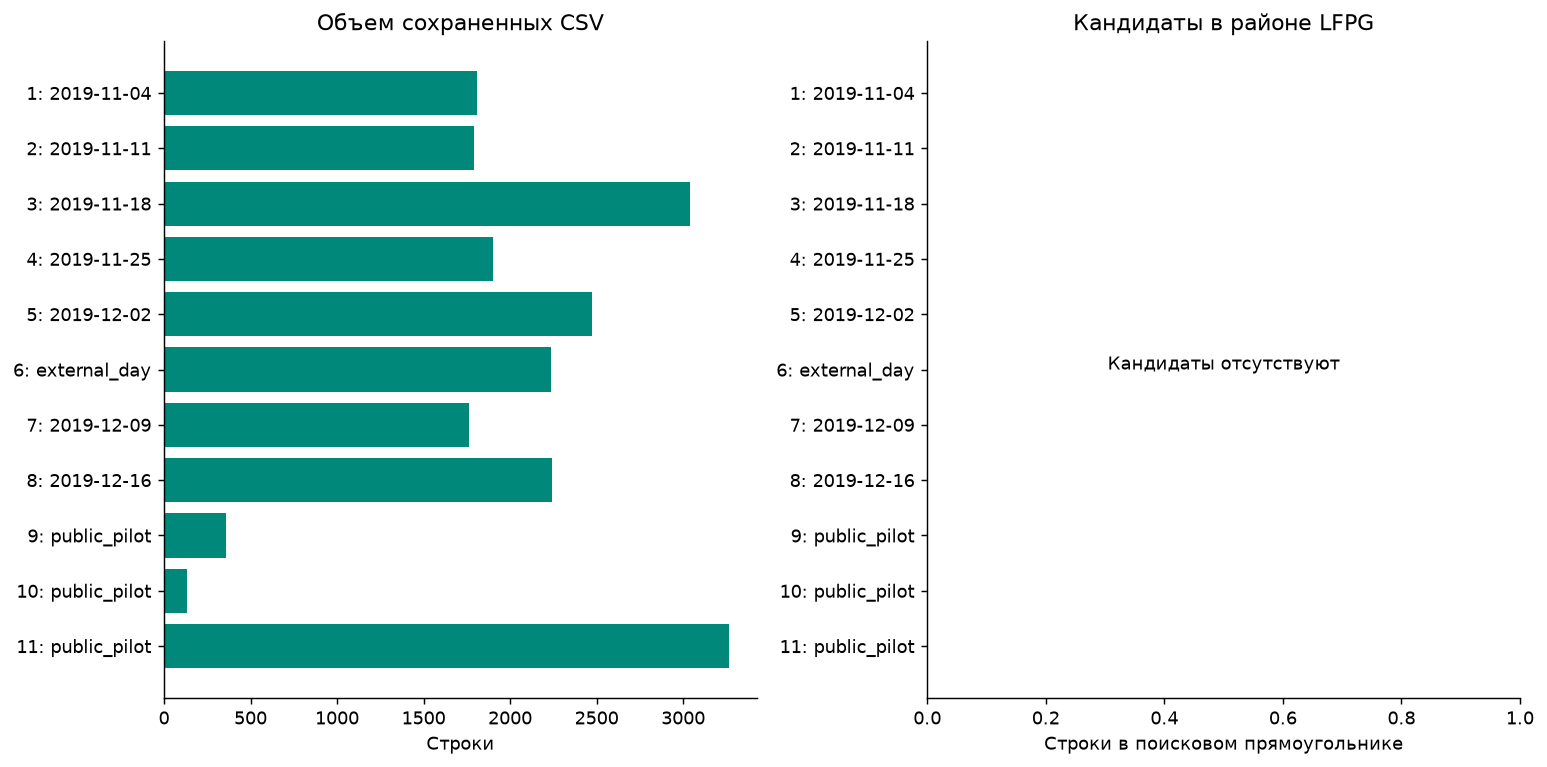

In [3]:
# Сравниваем объем файлов с пространственными кандидатами
labels = [str(i + 1) + ': ' + Path(p).parent.name for i, p in enumerate(inventory.source)]
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].barh(labels, inventory.rows, color=GREEN)
axes[0].set(title='Объем сохраненных CSV', xlabel='Строки')
axes[1].barh(labels, inventory.candidate_rows, color=RED)
axes[1].set(title='Кандидаты в районе LFPG', xlabel='Строки в поисковом прямоугольнике')
if inventory.candidate_rows.sum() == 0:
    axes[1].set_xlim(0, 1)
    axes[1].text(0.5, 0.5, 'Кандидаты отсутствуют', ha='center', transform=axes[1].transAxes)
for ax in axes:
    ax.invert_yaxis()
fig.tight_layout()
for ext in ['png', 'svg']:
    fig.savefig(BASE / f'figures/01_local_inventory.{ext}', bbox_inches='tight')
plt.show()

## Интерпретация и следующий шаг

Проверены 11 файлов; все контрольные суммы совпали с прежним манифестом. В широком поисковом прямоугольнике LFPG найдено 0 строк. Поля меток GoA в этих CSV отсутствуют.

Основной Parquet содержит flight_id, icao24, landing_time, attempt_times, ILS, n_attempts, GoA и метаданные C40. Его схема не содержит последовательного ряда координат, высоты, скорости и вертикальной скорости. Аэропортовые записи с метаданными C40 нельзя автоматически считать полными конечными траекториями.

Сохраненные пилоты не дают данных для эксперимента LFPG. Необходимо изучить происхождение основной таблицы и возможность получить ограниченный пилот временных рядов для выбранных полетов. До появления рядов нельзя обоснованно выбрать направление ВПП и проверить мониторинг до 300 ft.

Для следующего этапа требуется реестр источников с условиями доступа, датами, полями и возможностью связать наблюдения с попыткой захода. Массовая загрузка не входит в текущую инвентаризацию. Тема возможного доклада формируется после первого подтвержденного результата о качестве данных или поведении baseline.